In [41]:
import numpy as np
from math import factorial
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection

In [ ]:
def exp_taylor_series_term(n: int) :
    """Return a term of the taylor series as a function."""
    def term(x: np.complex128) -> np.complex128:
        return x ** n / factorial(n)
    return term

def exp_taylor_series(order: int) :
    """Return a taylor expnsion of exp as a function."""
    def taylor(x: np.complex128) -> np.complex128:
        result = 0
        for i in range(order):
            term = exp_taylor_series_term(i)
            result += term(x)
        return result
    return taylor

def plot_2d(func, lim: float = 5, mode: str = "phase", title: str = None,
            vmin: float = None, vmax: float = None, ax=None):
    """Plot a complex function in a 2d grid."""
    x = np.linspace(-lim, lim, 100)
    y = np.linspace(-lim, lim, 100)
    X, Y = np.meshgrid(x, y)
    Z = X + 1j * Y
    func_val = func(Z)

    if mode == "phase":
        disp_val = np.angle(func_val)
        cmap = "hsv"
        cbar_label = "Phase (rad)"
        vmin = -np.pi if vmin is None else vmin
        vmax = np.pi if vmax is None else vmax
    elif mode == "abs":
        disp_val = np.abs(func_val)
        cmap = "viridis"
        cbar_label = "|f(z)|"
    else:
        raise ValueError(f"Unknown mode: {mode}")

    own_fig = ax is None
    if own_fig:
        fig, ax = plt.subplots(figsize=(6, 6))
    else:
        fig = ax.figure

    im = ax.imshow(disp_val, extent=[-lim, lim, -lim, lim], origin="lower",
                   cmap=cmap, vmin=vmin, vmax=vmax)
    ax.set_xlabel("Re")
    ax.set_ylabel("Im")
    ax.set_title(title if title is not None else f"{mode} of f(z)")

    cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    cbar.set_label(cbar_label)
    if mode == "phase" and vmin == -np.pi and vmax == np.pi:
        cbar.set_ticks([-np.pi, -np.pi / 2, 0, np.pi / 2, np.pi])
        cbar.set_ticklabels(["-π", "-π/2", "0", "π/2", "π"])

    if own_fig:
        plt.show()
    return im

def plot_curve(func, t_range=(0, 2 * np.pi), n: int = 500, title: str = None,
               ax=None, label: str = None, color: str = None,
               colorbar: bool = True, cmap: str = "viridis"):
    """Plot a 1D curve t -> func(t) in the complex plane."""
    t = np.linspace(*t_range, n)
    val = func(t)
    if isinstance(val, tuple):
        x, y = val
    else:
        val = np.asarray(val, dtype=np.complex128)
        x, y = val.real, val.imag

    own_fig = ax is None
    if own_fig:
        fig, ax = plt.subplots(figsize=(6, 6))
    else:
        fig = ax.figure

    if color is not None:
        ax.plot(x, y, color=color, label=label)
        mappable = None
    else:
        points = np.column_stack([x, y]).reshape(-1, 1, 2)
        segments = np.concatenate([points[:-1], points[1:]], axis=1)
        lc = LineCollection(segments, cmap=cmap, array=0.5 * (t[:-1] + t[1:]),
                            label=label)
        ax.add_collection(lc)
        ax.autoscale()
        mappable = lc

    ax.set_xlabel("Re")
    ax.set_ylabel("Im")
    ax.set_aspect("equal", adjustable="datalim")
    ax.grid(alpha=0.5)
    if title is not None:
        ax.set_title(title)

    if mappable is not None and colorbar:
        cbar = fig.colorbar(mappable, ax=ax, fraction=0.046, pad=0.04)
        cbar.set_label("phi")

    if own_fig:
        plt.show()
    return ax

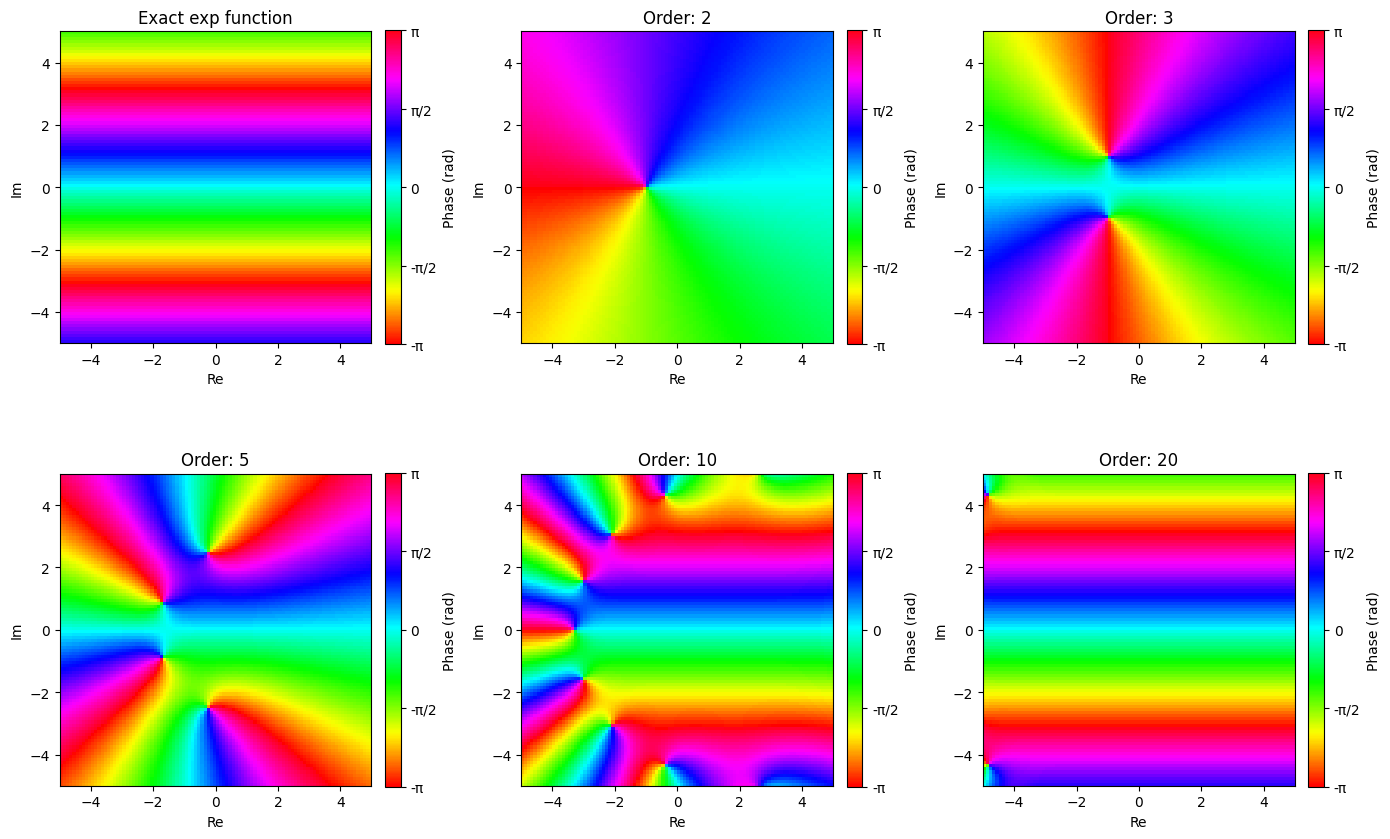

In [38]:
orders = [1, 2, 3, 5, 10, 20]
fig, axes = plt.subplots(2, 3, figsize=(14, 9))

for ax, order in zip(axes.flat, orders):
    if order == 1:
        plot_2d(np.exp, title=f"Exact exp function", ax=ax)
    else:
        plot_2d(exp_taylor_series(order), title=f"Order: {order}", ax=ax)

fig.tight_layout()
plt.show()


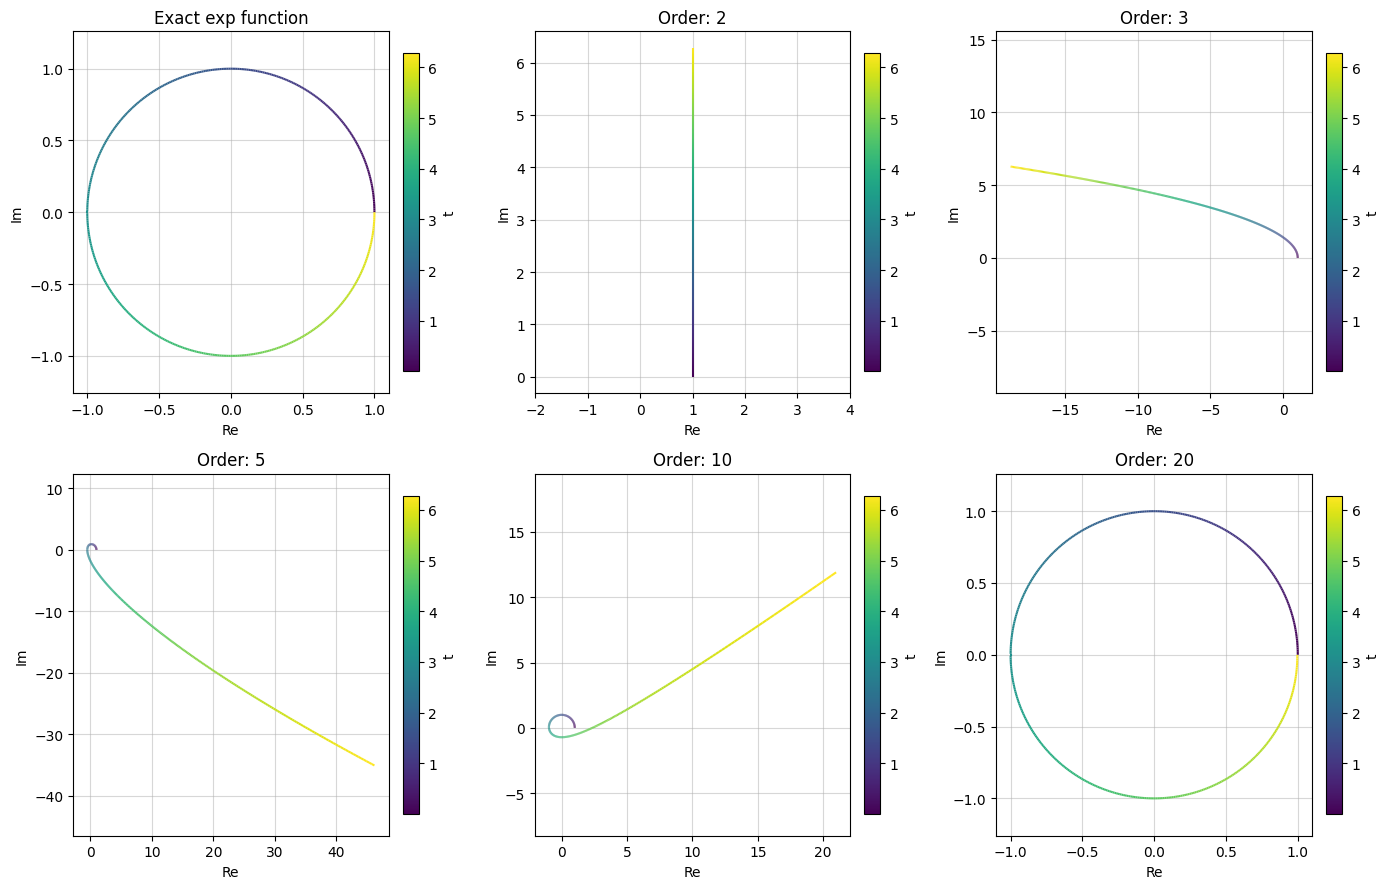

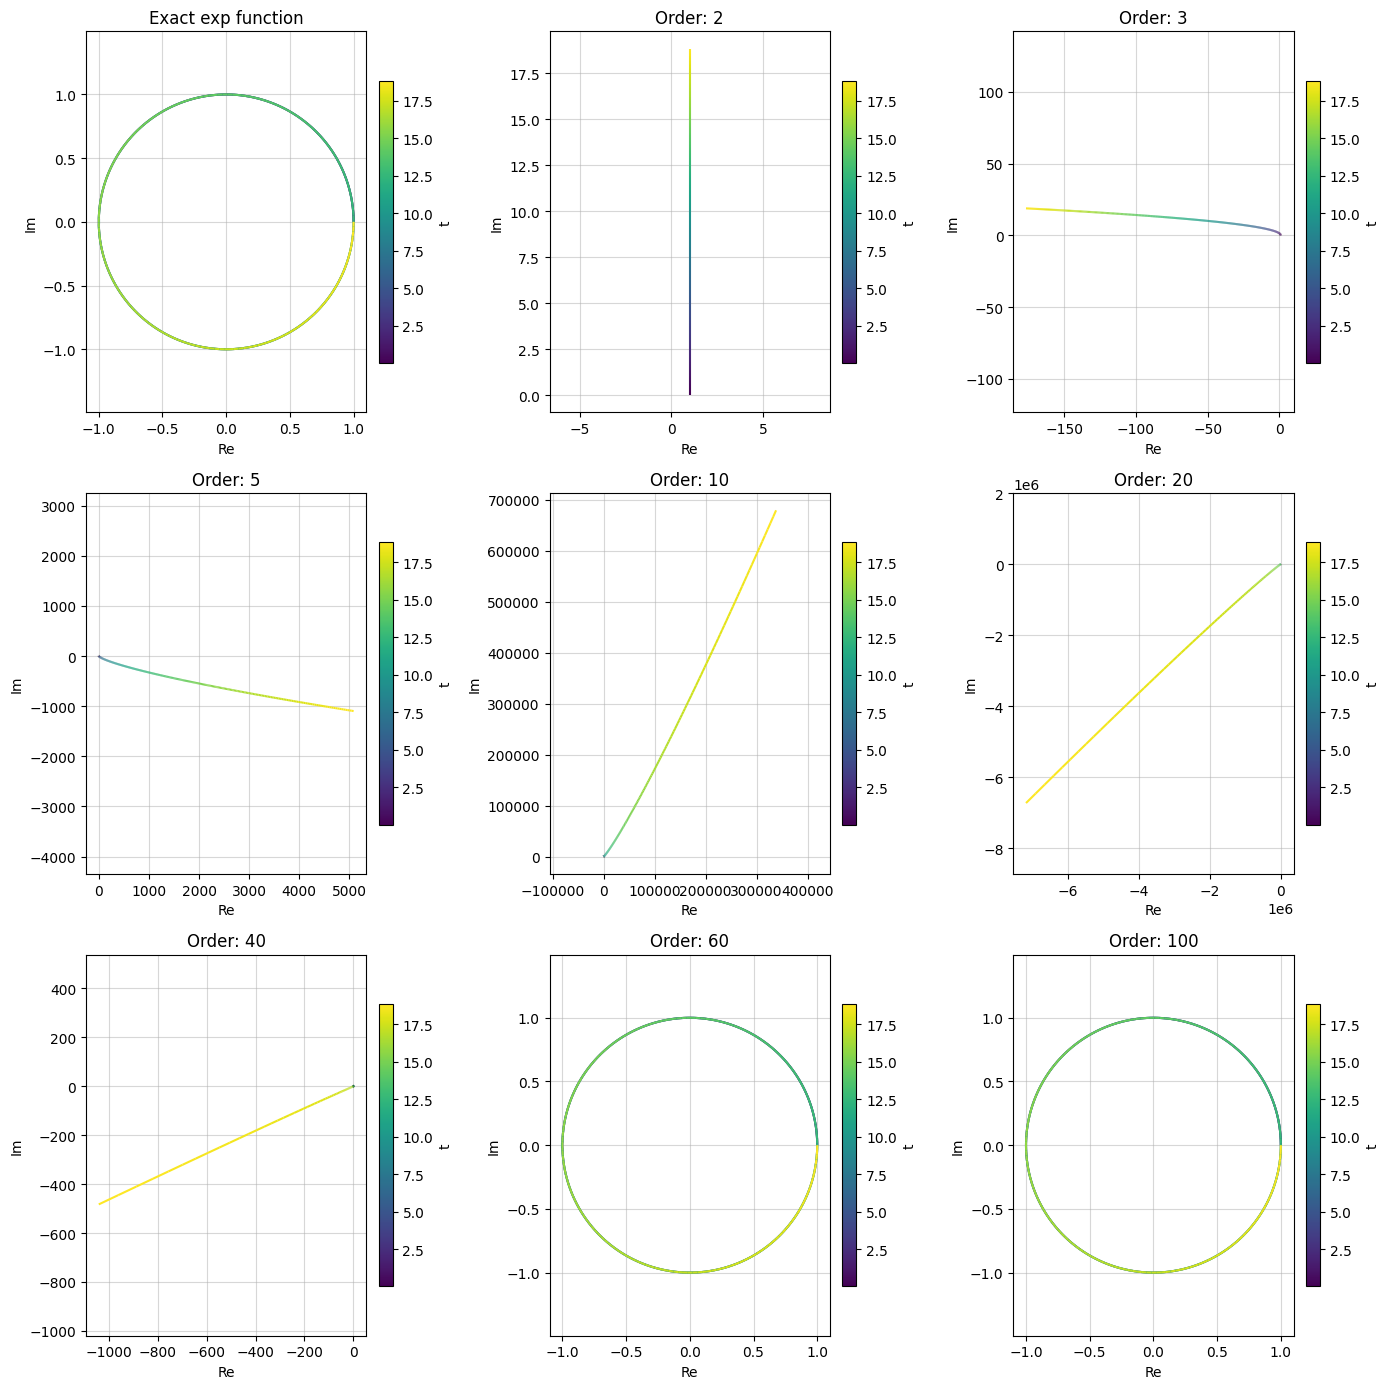

In [51]:
orders = [1, 2, 3, 5, 10, 20]
fig, axes = plt.subplots(2, 3, figsize=(14, 9))

for ax, order in zip(axes.flat, orders):
    if order == 1:
        plot_curve(lambda t: np.exp(1j * t), t_range=[0, 2*np.pi], title=f"Exact exp function", ax=ax)
    else:
        f = exp_taylor_series(order)
        plot_curve(lambda t, f=f: f(1j * t), t_range=[0, 2*np.pi], title=f"Order: {order}", ax=ax)

fig.tight_layout()
plt.show()

orders = [1, 2, 3, 5, 10, 20, 40, 60, 100]
fig, axes = plt.subplots(3, 3, figsize=(14, 14))

for ax, order in zip(axes.flat, orders):
    if order == 1:
        plot_curve(lambda t: np.exp(1j * t), t_range=[0, 6*np.pi], title=f"Exact exp function", ax=ax)
    else:
        f = exp_taylor_series(order)
        plot_curve(lambda t, f=f: f(1j * t), t_range=[0, 6*np.pi], title=f"Order: {order}", ax=ax)

fig.tight_layout()
plt.show()